In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def new_metric(X,Y,max=1):
    return np.max(np.abs(X-Y),axis=1)
    # return np.mean(
    #     np.flip(np.sort(np.abs(X-Y),axis=1),axis=1)[:,:max]
    #     ,axis=1
    # )
    #return np.abs(X-Y)


def min_metric(X,Y):
    return np.min(np.abs(X-Y),axis=1)

def thresh_metric(X,Y,thresh = 0.8):
    diff = np.square(X-Y)
    diff[diff<thresh] = 0
    return np.sqrt(np.sum(diff,axis=1))

def sample_spherical(npoints, ndim=3):
    vec = np.random.randn(ndim, npoints)
    vec /= np.linalg.norm(vec, axis=0)
    return vec

def euclidean(p1,p2):
    return np.linalg.norm(p1-p2,axis=1)


0 2
1 10
2 50
3 100
4 500
5 1000


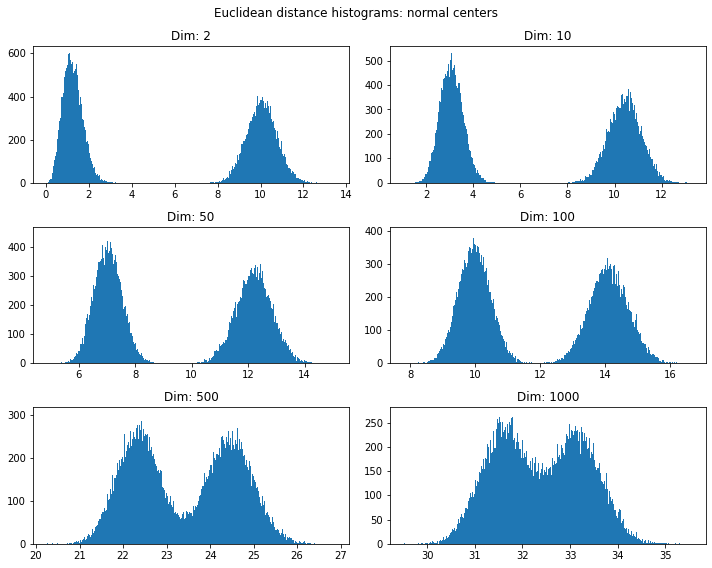

In [7]:
dims_list = [2,10,50,100,500,1000]
NUM_RUNS = 2
#dims_list =[2]
distance = "euclidean" # "thresh_metric"
center_type = 'normal'
#SEED = np.random.seed(42)
fig,ax = plt.subplots(3,2,figsize=(10,8))

for i,dims in enumerate(dims_list):
    print(i, dims)
    final_d1_flag = None
    for run in range(NUM_RUNS):
        c1 = np.array([0]*(dims))
                
        if center_type=='shifted':
            uniform_points = 10*sample_spherical(10000, dims).transpose()
            centre_index = np.random.choice(np.arange(len(uniform_points)))
            c2 = uniform_points[centre_index]
        else:
            c2 = np.array([10]+[0]*(dims-1))
        
        #SEED = np.random.seed(42)
        
        norm1 = np.random.multivariate_normal(c1,np.eye(dims), size=50000)
        norm2 = np.random.multivariate_normal(c2,np.eye(dims), size=50000)
        points = np.vstack([norm1,norm2])

        
        # ## EUCLIDEAN
        if distance=="euclidean":
            d1 = np.linalg.norm(points-c1,axis=1)               
        if distance=="new":            
            d1 = new_metric(points,c1)
        if distance=="min":
            d1 = min_metric(points,c1)   
        if distance=="check_dims":
            displacements = np.abs(points-c1)
        if distance=="thresh_metric":
            THRESH = 6
            d1 = thresh_metric(points,c1,thresh=THRESH)
        if final_d1_flag:
            final_d1 = final_d1+d1
        else:
            final_d1 = d1
            final_d1_flag = 1

    final_d1 = final_d1 / NUM_RUNS
    #diffs = np.square(points-c1)
    ax[i//2][i%2].hist(final_d1,bins=1000)
    # ax[i//2][i%2].hist(final_d1[:50000],bins=1000)
    # ax[i//2][i%2].hist(final_d1[50000:],bins=1000)
    ax[i//2][i%2].set_title(f'Dim: {dims}')

fig.suptitle(f'Euclidean distance histograms: {center_type} centers')
plt.tight_layout()
plt.savefig(f'/home/elef/tmp/plots/distance_histogram_subplots/euclidean_{center_type}_num_runs_{NUM_RUNS}.png')
plt.show()

# plt.hist(d1[:50000][d1[:50000]>0],bins=1000)
# plt.hist(d1[50000:][d1[50000:]>0],bins=1000,alpha=0.8)
# plt.savefig("../plots/thresh_metric/thresh_6_dims_500.png")
# plt.show()

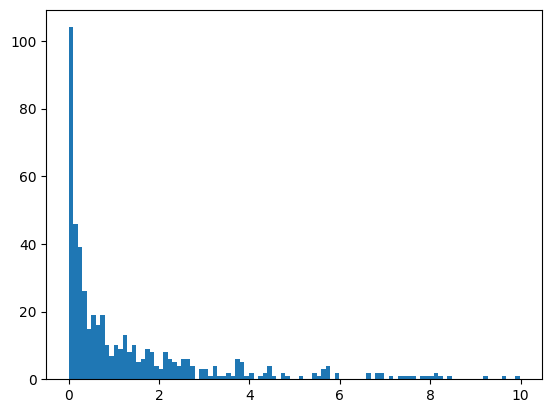

In [24]:
plt.hist(np.square(points[50010,:]-c1),bins=100)
plt.show()
# plt.savefig("../plots/c2_random_point_diff_histogram.png")
# plt.show()

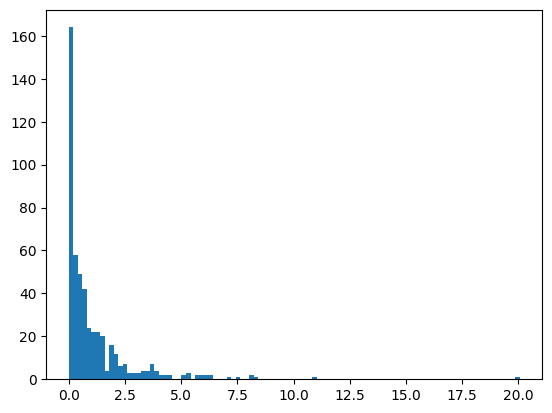

In [25]:
plt.hist(np.square(points[31,:]-c1),bins=100)
#plt.savefig("../plots/c1_random_point_diff_histogram.png")
plt.show()

## Conclusion

1. Distance values vary very very differently in different dimensions. Just because a two points are far apart in one dim does not mean the other dimensions have the same kind of distribution.
2. Thresholding is clearly very tough because even if you take the maximum difference dimension, doesn't guarantee that you are partioning along the correct one.
3. How do you define what's right? This problem is defined by us but if there is a higher displacement along another dimension, why wouldn't that be correct.

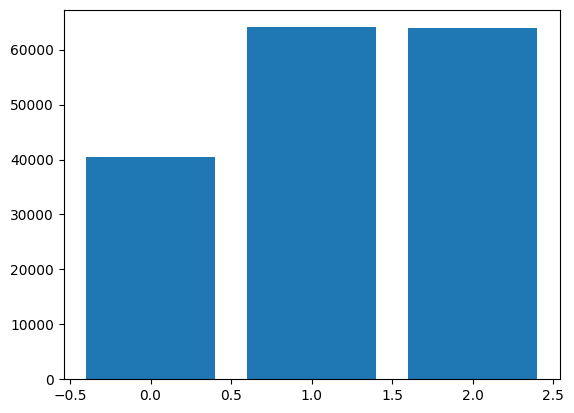

In [93]:
from sklearn.metrics.pairwise import euclidean_distances
np.random.seed(42)
dims = 100
random_points = np.random.choice(np.arange(1,100),size=(2,dims))
last_point = np.random.choice(np.arange(50,150),size=(1,dims))
random_points = np.vstack([random_points,last_point])
d1 = euclidean_distances(random_points)
# distances (1,2),(2,3),(1,3)
plt.bar(np.arange(3),np.tril(d1)[np.tril(d1)>0])
plt.show()

(2000, 1000)

In [7]:
from sklearn.metrics import pairwise_distances

def max_metric(p1,p2):
    diffs = np.square(p1-p2)
    
    max_met = np.sqrt(np.max(diffs))
    return max_met


def mul_max_metric(p1,p2,k=5):
    diffs = np.square(p1-p2)
    args = np.argsort(diffs)
    required_args = args[-5:]
    return np.mean(diffs[required_args])



In [17]:
from sklearn.metrics.pairwise import euclidean_distances
import tqdm

NUM_RUNS = 10
metric='mul_max_metric'
center_type='shifted'
SAVE = True
dims_list = [2,10,50,100,500,1000]
#dims_list = [100]
fig,ax = plt.subplots(2,2,figsize=(10,8))
for i,dims in enumerate(dims_list):
    t_dist_mat = None
    t_dist_mat_flag = None
    print("Starting runs for dim: ",dims)
    for run in tqdm.tqdm(range(NUM_RUNS)):
        c1 = np.array([0]*(dims))
                        
                
        if center_type=='shifted':
            uniform_points = 10*sample_spherical(1000,dims).transpose()
            centre_index = np.random.choice(np.arange(len(uniform_points)))
            c2 = uniform_points[centre_index]
        else:
            c2 = np.array([10]+[0]*(dims-1))


        norm1 = np.random.multivariate_normal(c1,np.eye(dims),size=1000)
        norm2 = np.random.multivariate_normal(c2,np.eye(dims),size=1000)
        points = np.vstack([norm1,norm2])

        if metric=='euclidean':
            dist_mat = euclidean_distances(points)
        elif metric=='max_metric':
            dist_mat = pairwise_distances(points,metric=max_metric)
        elif metric=='mul_max_metric':
            dist_mat = pairwise_distances(points,metric=mul_max_metric)
        if t_dist_mat_flag:
            t_dist_mat +=dist_mat
        else:
            t_dist_mat = dist_mat
            t_dist_mat_flag=1
    print("Runs done...")
    t_dist_mat = t_dist_mat/NUM_RUNS
    min_neighbor = t_dist_mat[np.arange(len(t_dist_mat)),np.argsort(t_dist_mat,axis=1)[:,1]]
    d_ratio = np.max(t_dist_mat,axis=1)/min_neighbor
    ax[i//2][i%2].hist(d_ratio,bins=100)
    ax[i//2][i%2].set_title(f"Dims: {dims}")  
    #plt.hist(d_ratio,bins=100,alpha=0.6)

fig.suptitle(f'{metric} Distance Ratio max/min')
plt.tight_layout()
if SAVE:
    plt.savefig(f"../plots/NN_histogram/{metric}_distance_{NUM_RUNS}_runs_{center_type}_center.png")
plt.show()
  

Starting runs for dim:  2


100%|██████████| 10/10 [01:17<00:00,  7.73s/it]


Runs done...
Starting runs for dim:  10


100%|██████████| 10/10 [01:20<00:00,  8.03s/it]


Runs done...
Starting runs for dim:  50


100%|██████████| 10/10 [01:38<00:00,  9.85s/it]


Runs done...
Starting runs for dim:  100


100%|██████████| 10/10 [02:08<00:00, 12.88s/it]


Runs done...
Starting runs for dim:  500


 40%|████      | 4/10 [02:51<04:17, 42.86s/it]